## Data Collection 

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('Telecom_Dataset.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe

<bound method NDFrame.describe of       customerID  gender  SeniorCitizen  ... MonthlyCharges TotalCharges  Churn
0     7590-VHVEG  Female              0  ...          29.85        29.85     No
1     5575-GNVDE    Male              0  ...          56.95       1889.5     No
2     3668-QPYBK    Male              0  ...          53.85       108.15    Yes
3     7795-CFOCW    Male              0  ...          42.30      1840.75     No
4     9237-HQITU  Female              0  ...          70.70       151.65    Yes
...          ...     ...            ...  ...            ...          ...    ...
7038  6840-RESVB    Male              0  ...          84.80       1990.5     No
7039  2234-XADUH  Female              0  ...         103.20       7362.9     No
7040  4801-JZAZL  Female              0  ...          29.60       346.45     No
7041  8361-LTMKD    Male              1  ...          74.40        306.6    Yes
7042  3186-AJIEK    Male              0  ...         105.65       6844.5     No

[7043

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## EDA

In [6]:
df['Churn']

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: object

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


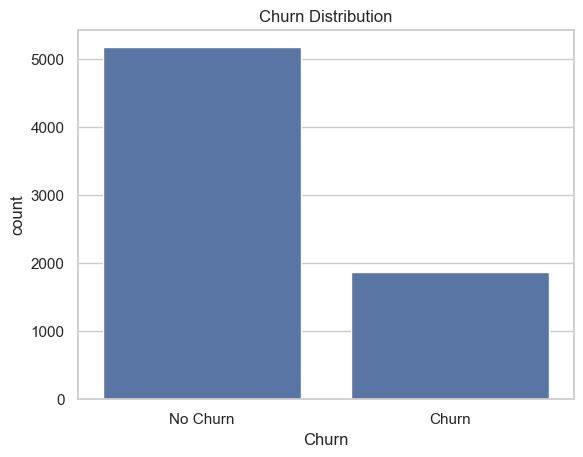

In [8]:
## Overall Churn Rate

churn_rate=df['Churn'].value_counts(normalize=True)
print(churn_rate)

sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.xticks([0,1],['No Churn','Churn'])
plt.show()

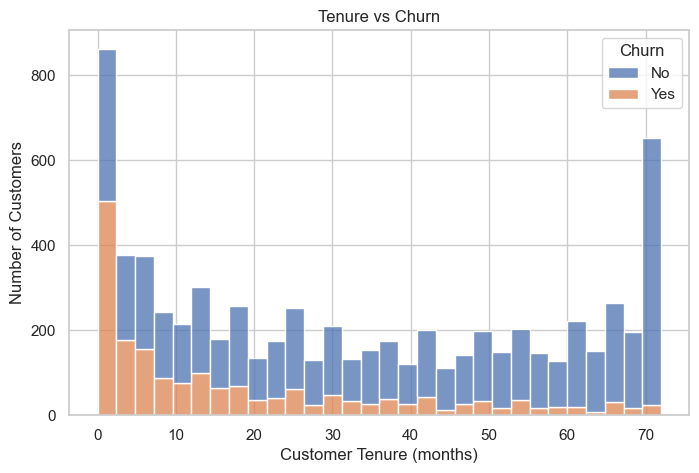

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30)
plt.title('Tenure vs Churn')
plt.xlabel("Customer Tenure (months)")
plt.ylabel("Number of Customers")
plt.xticks(range(0,80,10))
plt.show()

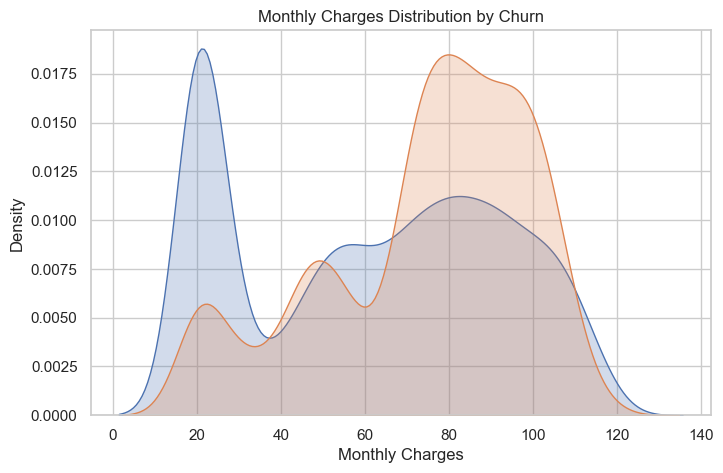

In [10]:
## Monthly Charges vs Churn
plt.figure(figsize=(8,5))
sns.kdeplot(df[df['Churn']=='No']['MonthlyCharges'], label='No Churn', fill=True)
sns.kdeplot(df[df['Churn']=='Yes']['MonthlyCharges'], label='Churn', fill=True)
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_5076\634686589.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.barplot(x='Contract',y='Churn', data=df.replace({'Yes':1,'No':0}))


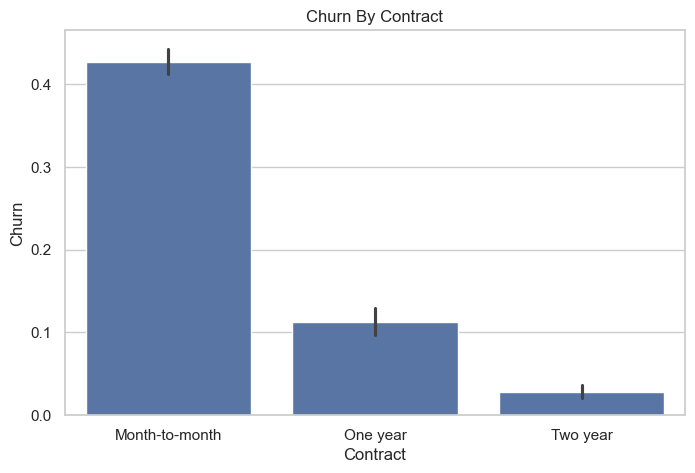

In [ ]:
## Bar Plot to see Churn rate by categorial features 

plt.figure(figsize=(8,5))
sns.barplot(x='Contract',y='Churn', data=df.replace({'Yes':1,'No':0}))
#sns.barplot(x='Contract',y=df[df['Churn']=='Yes'], data=df)
plt.title("Churn By Contract")
plt.xlabel('Contract')
plt.ylabel('Churn')
plt.show()

## Observation 
## Long tern tcontract client churn the most

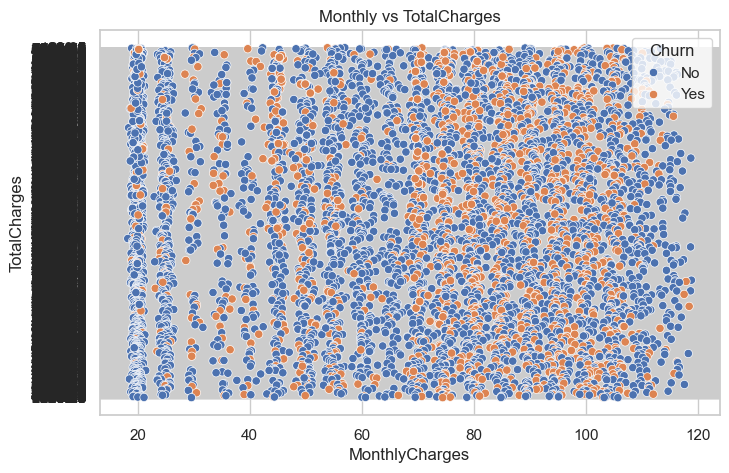

In [14]:
## Monthly Charges vs Total Charges Scatter  Plot

plt.figure(figsize=(8,5))
sns.scatterplot(x='MonthlyCharges', y='TotalCharges', hue='Churn', data=df)
plt.title('Monthly vs TotalCharges')
plt.show()

In [7]:
df['Churn']

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: object

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
## Correlation with Churn (Numeric Only)

df_encoded=df.copy()
df_encoded.select_dtypes(exclude=['int64','float64']).columns
df_encoded['Churn']=df_encoded['Churn'].map({'Yes':1,'No':0})
df_encoded.corr()['Churn'].sort_values(ascending=False)


## Feature Encoding

In [8]:
## Droping unnecessary columns 
cat_cols=df.select_dtypes(include='object').columns.tolist()
print(cat_cols)

['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [9]:
cat_cols.remove('customerID')

In [10]:
df.nunique() 

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [11]:
## Lets drop customer_id for as not seem useful
df_encoded=df.copy()
df_encoded.drop(['customerID'], axis=1,inplace=True)

In [12]:
## Applying encoding 
## On categorial type of columns

df_encoded['Churn']=df_encoded['Churn'].map({'Yes':1,'No':0})
cat_cols = df_encoded.select_dtypes(include='object').columns.tolist()
df_encoded=pd.get_dummies(df_encoded,columns=cat_cols,drop_first=True )

In [16]:
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TotalCharges_100.2,TotalCharges_100.25,TotalCharges_100.35,TotalCharges_100.4,TotalCharges_100.8,TotalCharges_100.9,TotalCharges_1001.2,TotalCharges_1001.5,TotalCharges_1003.05,TotalCharges_1004.35,...,TotalCharges_973.35,TotalCharges_973.45,TotalCharges_973.55,TotalCharges_973.65,TotalCharges_973.95,TotalCharges_978,TotalCharges_978.6,TotalCharges_979.05,TotalCharges_979.5,TotalCharges_98.35,TotalCharges_98.5,TotalCharges_980.35,TotalCharges_981.45,TotalCharges_982.95,TotalCharges_985.05,TotalCharges_987.95,TotalCharges_989.05,TotalCharges_989.45,TotalCharges_99.45,TotalCharges_99.6,TotalCharges_99.75,TotalCharges_99.95,TotalCharges_990.3,TotalCharges_990.45,TotalCharges_990.85,TotalCharges_990.9,TotalCharges_992.7,TotalCharges_993.15,TotalCharges_994.55,TotalCharges_994.8,TotalCharges_995.35,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9
0,0,1,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,34,56.95,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,2,53.85,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,45,42.30,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,2,70.70,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [14]:
## After one-hot encoding using get_dummies() all categorial columns converted into bool but for models like -XGBoost and RandomForest - need integers values

df_encoded=df_encoded.astype({col:int for col in df_encoded.select_dtypes('bool').columns})

In [17]:
##Train Test Split 

from sklearn.model_selection import train_test_split

X=df_encoded.drop(['Churn'], axis=1)
y=df_encoded['Churn']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y) ##startify maintains both train and test have same proportion ofchurn ratio 

In [18]:
print('Train Churn Rate', y_train.value_counts(normalize=True))
print('Test Churn Rate',y_test.value_counts(normalize=True))

Train Churn Rate Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Test Churn Rate Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## Model Selection and Building

In [19]:
## LogisticRegression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

log_model=LogisticRegression(max_iter=1000)
log_model.fit(X_train,y_train)
y_pred=log_model.predict(X_test)

print("Accuracy:",accuracy_score(y_test,y_pred))
print("\n Classification Report:\n", classification_report(y_test,y_pred))
print("\n Confusion Matrix:\n",confusion_matrix(y_test,y_pred))

Accuracy: 0.794180269694819

 Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409


 Confusion Matrix:
 [[917 118]
 [172 202]]


In [21]:
## Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model=RandomForestClassifier(n_estimators=100 , class_weight='balanced',random_state=42)
rf_model.fit(X_train,y_train)
y_pred_rf=rf_model.predict(X_test)

print("Accuracy:",accuracy_score(y_test,y_pred_rf))
print("\nClassification Report:\n",classification_report(y_test,y_pred_rf))
print("\nConfusion Matrix:",confusion_matrix(y_test,y_pred_rf))

Accuracy: 0.7991483321504613

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Confusion Matrix: [[938  97]
 [186 188]]


In [25]:
## XGBoost 

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

xgb_model=XGBClassifier(n_estimators=300,use_label_encoder=False, learning_rate=0.1,max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,eval_metric='logloss', random_state=42)
xgb_model.fit(X_train,y_train)
y_pred_xgb= xgb_model.predict(X_test)
print("XGBOOST Accuracy:", accuracy_score(y_test,y_pred_xgb))
print("\n Classification Report:", classification_report(y_test,y_pred_xgb))
print("\n Confusion Matrix:\n", confusion_matrix(y_test,y_pred_xgb))


XGBOOST Accuracy: 0.7920511000709723

 Classification Report:               precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409


 Confusion Matrix:
 [[916 119]
 [174 200]]
